In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

import os
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [51]:
data_path = "../outputs"

features = pd.read_csv(f"{data_path}/patient_features.csv")

print("Patient feature dataset loaded successfully!")
print("Dataset shape:", features.shape)

display(features.head())

Patient feature dataset loaded successfully!
Dataset shape: (50000, 14)


,patient_id,home_hospital_id,gender,age,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Growth,Seasonality,No_Growth_Baseline,Has_OPD_Visit
0,P000001,H004,Male,60,249.0,3.0,4957.45,0.0,0.0,1.0,-50.0,2.486326,False,1
1,P000002,H002,Male,29,433.0,1.0,2429.05,0.0,0.0,1.0,-100.0,3.464102,False,1
2,P000003,H003,Male,28,117.0,6.0,26877.75,5.0,4.0,6.0,-50.0,1.348400,False,1
3,P000004,H001,Female,35,36.0,4.0,11662.68,0.0,0.0,5.0,200.0,1.954017,False,1
4,P000005,H002,Male,34,150.0,1.0,9362.15,0.0,0.0,1.0,0.0,3.464102,True,1


In [52]:
print("Dataset Information:")
features.info()

print("\nMissing Values:")
print(features.isnull().sum())

print("\nDuplicate Patient IDs:")
print(features["patient_id"].duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           50000 non-null  object 
 1   home_hospital_id     50000 non-null  object 
 2   gender               50000 non-null  object 
 3   age                  50000 non-null  int64  
 4   Recency              50000 non-null  float64
 5   Frequency            50000 non-null  float64
 6   Monetary             50000 non-null  float64
 7   Admission_Frequency  50000 non-null  float64
 8   Average_LOS          50000 non-null  float64
 9   Lab_Frequency        50000 non-null  float64
 10  Growth               50000 non-null  float64
 11  Seasonality          50000 non-null  float64
 12  No_Growth_Baseline   50000 non-null  bool   
 13  Has_OPD_Visit        50000 non-null  int64  
dtypes: bool(1), float64(8), int64(2), object(3)
memory usage: 5.0+ MB

In [53]:
clustering_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Admission_Frequency",
    "Average_LOS",
    "Lab_Frequency",
    "Seasonality"
]

X = features[clustering_features].copy()

print("Selected clustering features:")
display(X.head())

print("\nSelected feature shape:", X.shape)

Selected clustering features:


,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
0,249.0,3.0,4957.45,0.0,0.0,1.0,2.486326
1,433.0,1.0,2429.05,0.0,0.0,1.0,3.464102
2,117.0,6.0,26877.75,5.0,4.0,6.0,1.348400
3,36.0,4.0,11662.68,0.0,0.0,5.0,1.954017
4,150.0,1.0,9362.15,0.0,0.0,1.0,3.464102



Selected feature shape: (50000, 7)


In [54]:
print("Missing values in selected features:")
print(X.isnull().sum())

print("\nInfinite values:")
print(np.isinf(X).sum())

print("\nNegative values:")
print((X < 0).sum())

Missing values in selected features:
Recency                0
Frequency              0
Monetary               0
Admission_Frequency    0
Average_LOS            0
Lab_Frequency          0
Seasonality            0
dtype: int64

Infinite values:
Recency                0
Frequency              0
Monetary               0
Admission_Frequency    0
Average_LOS            0
Lab_Frequency          0
Seasonality            0
dtype: int64

Negative values:
Recency                0
Frequency              0
Monetary               0
Admission_Frequency    0
Average_LOS            0
Lab_Frequency          0
Seasonality            0
dtype: int64


In [55]:
X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median())

print("Missing and infinite values handled.")

print("\nRemaining missing values:")
print(X.isnull().sum().sum())

Missing and infinite values handled.

Remaining missing values:
0


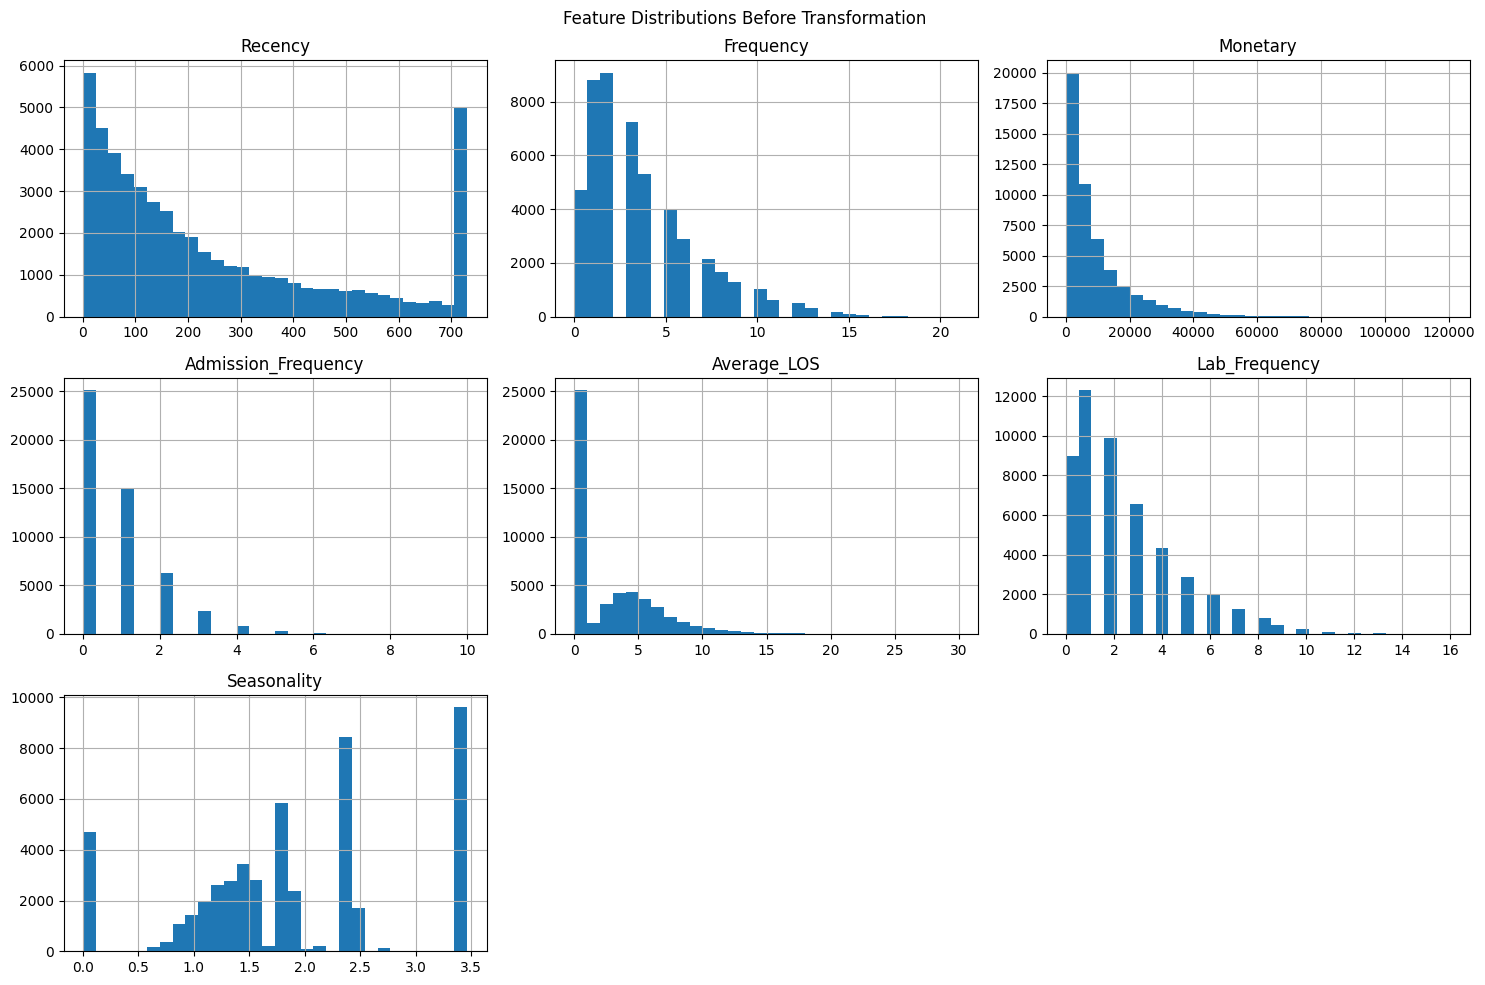

In [56]:
X.hist(figsize=(15, 10), bins=30)

plt.suptitle("Feature Distributions Before Transformation")
plt.tight_layout()
plt.show()

In [57]:
log_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Admission_Frequency",
    "Average_LOS",
    "Lab_Frequency",
    "Seasonality"
]

X_log = X.copy()

X_log[log_features] = np.log1p(X_log[log_features])

print("Log transformation completed!")

display(X_log.head())

Log transformation completed!


,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
0,5.521461,1.386294,8.508848,0.000000,0.000000,0.693147,1.248849
1,6.073045,0.693147,7.795667,0.000000,0.000000,0.693147,1.496068
2,4.770685,1.945910,10.199091,1.791759,1.609438,1.945910,0.853734
3,3.610918,1.609438,9.364235,0.000000,0.000000,1.791759,1.083166
4,5.017280,0.693147,9.144537,0.000000,0.000000,0.693147,1.496068


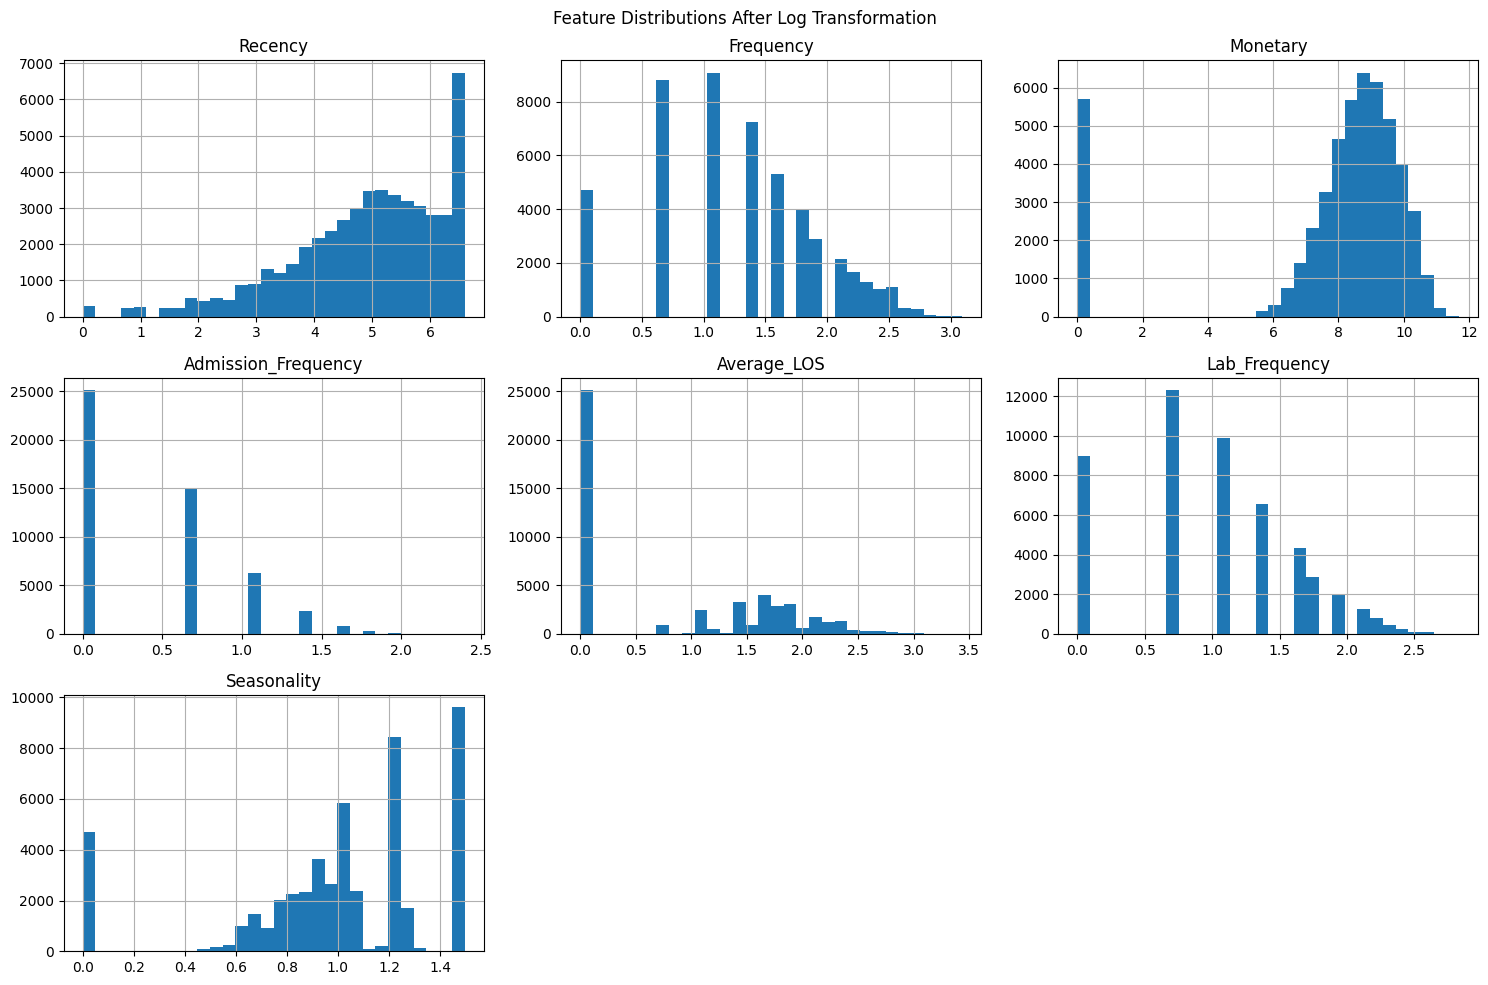

In [58]:
X_log.hist(figsize=(15, 10), bins=30)

plt.suptitle("Feature Distributions After Log Transformation")
plt.tight_layout()
plt.show()

In [59]:
X_capped = X_log.copy()

for column in X_capped.columns:
    lower_limit = X_capped[column].quantile(0.01)
    upper_limit = X_capped[column].quantile(0.99)

    X_capped[column] = X_capped[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier capping completed!")

display(X_capped.describe())

Outlier capping completed!


,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,4.894158,1.313608,7.751837,0.450431,0.854399,1.021386,0.993018
std,1.317100,0.668915,2.947589,0.495969,0.915596,0.642369,0.408205
min,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.127134,0.693147,7.651366,0.000000,0.000000,0.693147,0.827274
50%,5.081404,1.386294,8.630124,0.000000,0.000000,1.098612,1.032853
75%,5.926926,1.791759,9.411798,0.693147,1.734601,1.386294,1.204622
max,6.594413,2.639057,10.768498,1.609438,2.708050,2.302585,1.496068


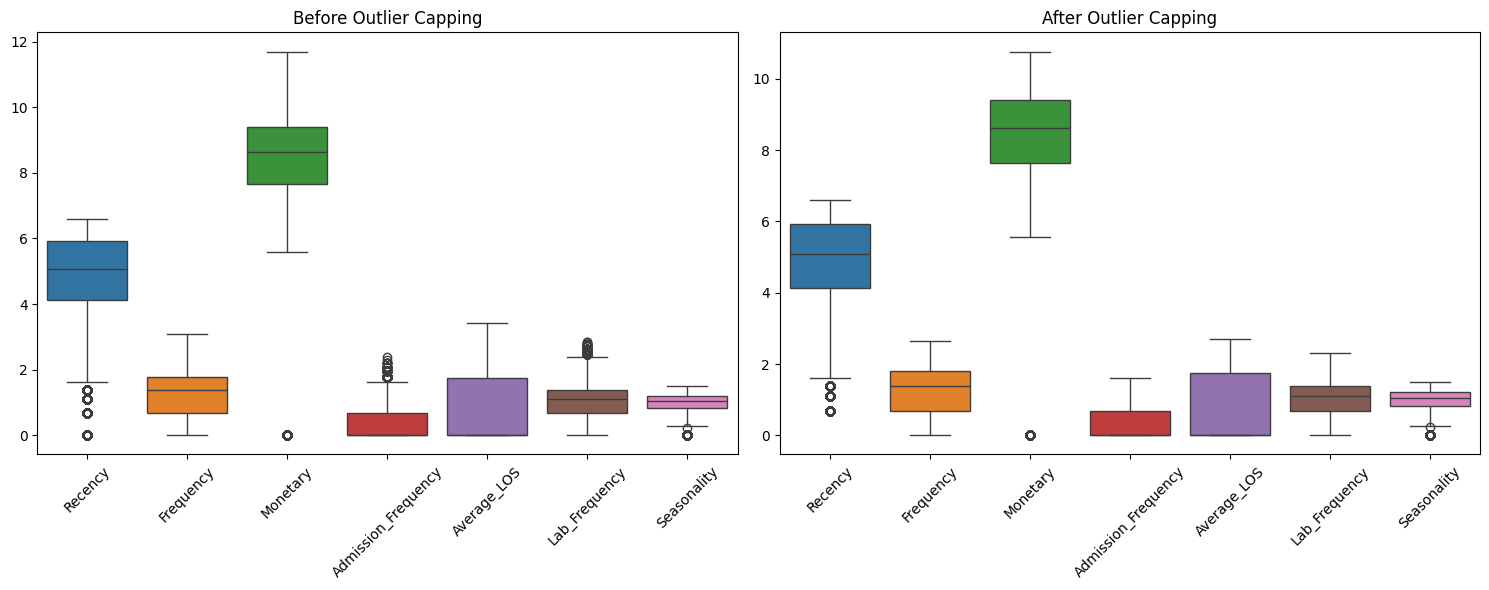

In [60]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.boxplot(data=X_log)
plt.title("Before Outlier Capping")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(data=X_capped)
plt.title("After Outlier Capping")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [61]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_capped)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=clustering_features
)

print("Feature scaling completed!")

display(X_scaled.head())

Feature scaling completed!


,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
0,0.476281,0.108664,0.256826,-0.908192,-0.93317,-0.510987,0.626728
1,0.895072,-0.927572,0.014870,-0.908192,-0.93317,-0.510987,1.232359
2,-0.093747,0.945274,0.830264,2.336875,0.82465,1.439255,-0.341213
3,-0.974302,0.442257,0.547028,-0.908192,-0.93317,1.199281,0.220843
4,0.093481,-0.927572,0.472493,-0.908192,-0.93317,-0.510987,1.232359


In [62]:
print("Mean of scaled features:")
display(X_scaled.mean().round(3))

print("\nStandard deviation of scaled features:")
display(X_scaled.std().round(3))

Mean of scaled features:


Recency                0.0
Frequency              0.0
Monetary              -0.0
Admission_Frequency    0.0
Average_LOS            0.0
Lab_Frequency          0.0
Seasonality           -0.0
dtype: float64


Standard deviation of scaled features:


Recency                1.0
Frequency              1.0
Monetary               1.0
Admission_Frequency    1.0
Average_LOS            1.0
Lab_Frequency          1.0
Seasonality            1.0
dtype: float64

In [63]:
processed_features = pd.concat(
    [
        features[["patient_id"]].reset_index(drop=True),
        X_scaled.reset_index(drop=True)
    ],
    axis=1
)

print("Final processed dataset shape:", processed_features.shape)

display(processed_features.head())

Final processed dataset shape: (50000, 8)


,patient_id,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
0,P000001,0.476281,0.108664,0.256826,-0.908192,-0.93317,-0.510987,0.626728
1,P000002,0.895072,-0.927572,0.014870,-0.908192,-0.93317,-0.510987,1.232359
2,P000003,-0.093747,0.945274,0.830264,2.336875,0.82465,1.439255,-0.341213
3,P000004,-0.974302,0.442257,0.547028,-0.908192,-0.93317,1.199281,0.220843
4,P000005,0.093481,-0.927572,0.472493,-0.908192,-0.93317,-0.510987,1.232359


In [64]:
output_path = "../outputs/processed_data"

os.makedirs(output_path, exist_ok=True)

processed_features.to_csv(
    f"{output_path}/patient_features_scaled.csv",
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [65]:
print("Final Dataset Shape:", processed_features.shape)

print("\nMissing Values:")
print(processed_features.isnull().sum().sum())

print("\nDuplicate Patient IDs:")
print(processed_features["patient_id"].duplicated().sum())

print("\nFinal Dataset Preview:")
display(processed_features.head())

Final Dataset Shape: (50000, 8)

Missing Values:
0

Duplicate Patient IDs:
0

Final Dataset Preview:


,patient_id,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
0,P000001,0.476281,0.108664,0.256826,-0.908192,-0.93317,-0.510987,0.626728
1,P000002,0.895072,-0.927572,0.014870,-0.908192,-0.93317,-0.510987,1.232359
2,P000003,-0.093747,0.945274,0.830264,2.336875,0.82465,1.439255,-0.341213
3,P000004,-0.974302,0.442257,0.547028,-0.908192,-0.93317,1.199281,0.220843
4,P000005,0.093481,-0.927572,0.472493,-0.908192,-0.93317,-0.510987,1.232359
